# 02 Make the 224 px image cache

**AI-Assisted Mineral Identification — Capstone, Fall 2026 (SO-1, SO-2)**

Fits every image in `splits.csv` to the input size 224×224 one time.

What it does:
1. Checks that `splits.csv` is the committed version (SHA-256).
2. Letterboxes each image: rotates it according to its camera EXIF tag, scales its long side to 224 px, and fills the remaining space with the ImageNet mean color.
3. Writes one zip per priority group, laid out as `<split>/<class>/<id>.jpg`.
4. Writes an index per group linking each cached image back to its original file, plus `cache_meta.json`.

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, io, json, time, shutil, hashlib, zipfile, platform, datetime
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import PIL
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from IPython.display import display

## 2. Configuration

`IMG_SIZE`, `PAD_COLOR` and `JPEG_QUALITY` are shared preprocessing settings.

In [ ]:
# ---- Drive paths ----
DATA_DIR   = "/content/drive/MyDrive/CSE_Capstone_Data/mineral-photos"
SPLITS_DIR = "/content/drive/MyDrive/CSE_Capstone_Data/splits"
CACHE_DIR  = "/content/drive/MyDrive/CSE_Capstone_Data/cache_224"
LOCAL_TMP  = "/content/cache_tmp"     # local cache

# Committed splits.csv (printed by section 9 of 01_make_splits)
EXPECTED_SPLITS_SHA = "24f264149e95f3cc4d442f1394032b60dbf2579e590638a601f3c7bb2fa937ed"

# ---- Shared preprocessing settings ----
IMG_SIZE     = 224
PAD_COLOR    = (124, 116, 104)        # ImageNet mean (0.485, 0.456, 0.406) x 255, to scale to RGB
RESAMPLE     = Image.Resampling.BICUBIC
JPEG_QUALITY = 95
NUM_WORKERS  = 32

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(LOCAL_TMP, exist_ok=True)

## 3. Load and verify the splits

In [ ]:
csv_path = os.path.join(SPLITS_DIR, "splits.csv")
with open(csv_path, "rb") as fh:
    splits_sha = hashlib.sha256(fh.read()).hexdigest()
assert splits_sha == EXPECTED_SPLITS_SHA, (
    f"splits.csv does not match the committed version.\n  found:    {splits_sha}\n  expected: {EXPECTED_SPLITS_SHA}")

splits = pd.read_csv(csv_path)
with open(os.path.join(SPLITS_DIR, "splits_meta.json")) as fh:
    GROUPS = json.load(fh)["groups"]

# Label = position of the class in alphabetical order within its group (the order ImageFolder uses)
LABELS = {g: {c: i for i, c in enumerate(sorted(cs))} for g, cs in GROUPS.items()}
splits["label"] = [LABELS[g][c] for g, c in zip(splits.group, splits["class"])]

print(f"splits.csv verified: {len(splits)} images")
display(pd.crosstab(splits.group, splits.split).reindex(columns=["train", "val", "test"]))
for g, m in LABELS.items():
    print(f"  {g:6} labels: {m}")

splits.csv verified: 39349 images


split,train,val,test
group,,,
high,13412,2880,2874
low,9154,1953,1962
medium,4980,1069,1065


  high   labels: {'baryte': 0, 'beryl': 1, 'copper': 2, 'fluorite': 3, 'quartz': 4}
  medium labels: {'azurite': 0, 'cerussite': 1, 'malachite': 2, 'pyromorphite': 3, 'smithsonite': 4}
  low    labels: {'calcite': 0, 'gypsum': 1, 'hematite': 2, 'pyrite': 3, 'wulfenite': 4}


## 4. Letterbox function

For JPEGs, `draft` lets the decoder skip detail that would be thrown away anyway (it never goes below 224 px), which makes reading large photos much faster. -Claude

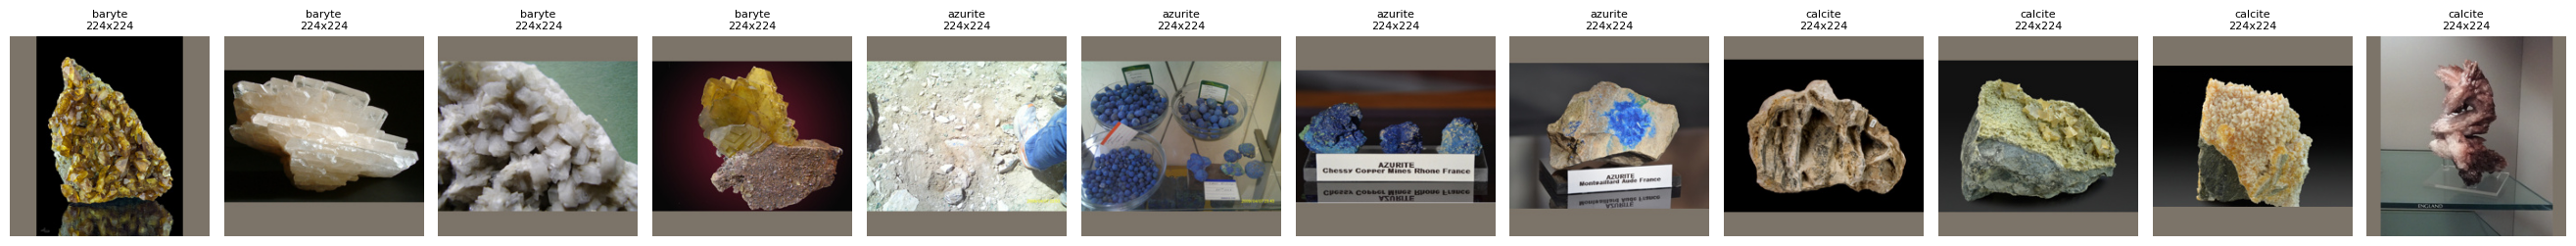

In [ ]:
def letterbox(rel_path):
    with Image.open(os.path.join(DATA_DIR, rel_path)) as im:
        im.draft("RGB", (IMG_SIZE, IMG_SIZE))      # JPEG only; result stays >= 224 px on both sides
        im = ImageOps.exif_transpose(im)           # same camera rotation used in 01_make_splits
        im = im.convert("RGB")
        im = ImageOps.pad(im, (IMG_SIZE, IMG_SIZE), method=RESAMPLE, color=PAD_COLOR, centering=(0.5, 0.5))
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=JPEG_QUALITY, subsampling=0)
    return buf.getvalue()

# Quick visual check on a few images before the long run
sample = splits.groupby("group").head(4)
fig_imgs = [Image.open(io.BytesIO(letterbox(p))) for p in sample.rel_path]
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(fig_imgs), figsize=(2.2 * len(fig_imgs), 2.6))
for ax, im, (_, r) in zip(axes, fig_imgs, sample.iterrows()):
    ax.imshow(im); ax.set_title(f"{r['class']}\n{im.size[0]}x{im.size[1]}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Build the cache

In [ ]:
def sha256_file(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

meta_path = os.path.join(CACHE_DIR, "cache_meta.json")
meta = json.load(open(meta_path)) if os.path.exists(meta_path) else {"groups": {}}

for group in GROUPS:
    zip_name, index_name = f"{group}_{IMG_SIZE}.zip", f"{group}_{IMG_SIZE}_index.csv"
    drive_zip = os.path.join(CACHE_DIR, zip_name)
    done = meta["groups"].get(group)
    if done and os.path.exists(drive_zip) and os.path.getsize(drive_zip) == done["zip_bytes"]:
        print(f"[{group}] already cached, skipping")
        continue

    part = splits[splits.group == group].sort_values(["split", "class", "rel_path"]).reset_index(drop=True)
    part["id"] = np.arange(len(part))
    part["zip_path"] = [f"{s}/{c}/{i:06d}.jpg" for s, c, i in zip(part.split, part["class"], part.id)]

    local_zip = os.path.join(LOCAL_TMP, zip_name)
    t0, errors = time.time(), []
    with zipfile.ZipFile(local_zip, "w", compression=zipfile.ZIP_STORED) as zf, ThreadPoolExecutor(NUM_WORKERS) as ex:
        def safe(p):
            try:
                return letterbox(p)
            except Exception as e:
                return e
        for zp, rp, out in tqdm(zip(part.zip_path, part.rel_path, ex.map(safe, part.rel_path)),
                                total=len(part), desc=f"[{group}]"):
            if isinstance(out, Exception):
                errors.append((rp, f"{type(out).__name__}: {out}"))
            else:
                zf.writestr(zp, out)
    assert not errors, f"[{group}] {len(errors)} images failed (they were readable in 01_make_splits): {errors[:5]}"

    index_local = os.path.join(LOCAL_TMP, index_name)
    part[["id", "zip_path", "rel_path", "class", "label", "split"]].to_csv(index_local, index=False, lineterminator="\n")
    zip_sha = sha256_file(local_zip)
    shutil.copy(local_zip, drive_zip)
    shutil.copy(index_local, os.path.join(CACHE_DIR, index_name))

    meta["groups"][group] = {
        "zip": zip_name, "index": index_name, "n_images": int(len(part)),
        "zip_bytes": os.path.getsize(local_zip), "zip_sha256": zip_sha,
        "labels": LABELS[group],
        "counts": {s: int(n) for s, n in part.split.value_counts().items()},
    }
    meta.update({
        "splits_csv_sha256": splits_sha, "img_size": IMG_SIZE, "pad_color": list(PAD_COLOR),
        "resize": "letterbox: EXIF rotate, long side to IMG_SIZE (bicubic), centered, pad with pad_color",
        "jpeg_quality": JPEG_QUALITY, "jpeg_subsampling": "4:4:4",
        "updated_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        "versions": {"python": platform.python_version(), "pillow": PIL.__version__, "numpy": np.__version__},
    })
    with open(meta_path, "w") as fh:
        json.dump(meta, fh, indent=2)
    os.remove(local_zip)
    print(f"[{group}] {len(part)} images, {meta['groups'][group]['zip_bytes'] / 1e6:.0f} MB, "
          f"{(time.time() - t0) / 60:.1f} min. Saved to Drive.")

[high]:   0%|          | 0/19166 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/JpegImagePlugin.py:887: UserWarning: Image appears to be a malformed MPO file, it will be interpreted as a base JPEG file
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 0. 
  warnings.warn(str(msg))


[high] 19166 images, 398 MB, 7.9 min. Saved to Drive.


[medium]:   0%|          | 0/7114 [00:00<?, ?it/s]

[medium] 7114 images, 191 MB, 3.0 min. Saved to Drive.


[low]:   0%|          | 0/13069 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 12 bytes but only got 2. 
  warnings.warn(str(msg))


[low] 13069 images, 299 MB, 33.2 min. Saved to Drive.


## 6. Verify the cache

[high] OK: 19166 images, checksum matches, counts match splits.csv
[medium] OK: 7114 images, checksum matches, counts match splits.csv
[low] OK: 13069 images, checksum matches, counts match splits.csv


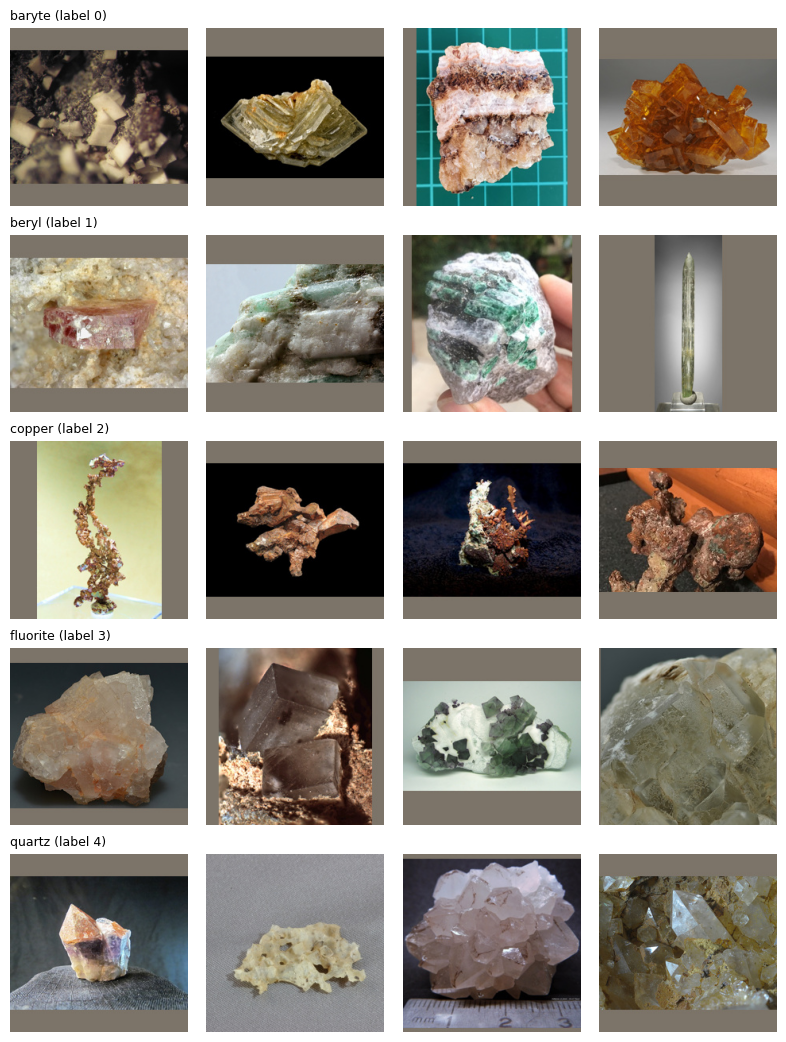

In [ ]:
SPLITS = ["train", "val", "test"]
for group in GROUPS:
    g = meta["groups"][group]
    drive_zip = os.path.join(CACHE_DIR, g["zip"])
    assert sha256_file(drive_zip) == g["zip_sha256"], f"[{group}] zip on Drive does not match its checksum"
    idx = pd.read_csv(os.path.join(CACHE_DIR, g["index"]))
    with zipfile.ZipFile(drive_zip) as zf:
        names = set(zf.namelist())
        assert names == set(idx.zip_path), f"[{group}] zip contents do not match the index"
        with Image.open(io.BytesIO(zf.read(idx.zip_path.iloc[0]))) as im:
            assert im.size == (IMG_SIZE, IMG_SIZE) and im.mode == "RGB"
    expected = splits[splits.group == group].split.value_counts()
    assert idx.split.value_counts().reindex(SPLITS).equals(expected.reindex(SPLITS)), f"[{group}] split counts differ"
    print(f"[{group}] OK: {len(idx)} images, checksum matches, counts match splits.csv")

# Visual check
group = "high"
g = meta["groups"][group]
idx = pd.read_csv(os.path.join(CACHE_DIR, g["index"]))
classes = sorted(g["labels"], key=g["labels"].get)
fig, axes = plt.subplots(len(classes), 4, figsize=(8, 2.1 * len(classes)), squeeze=False)
with zipfile.ZipFile(os.path.join(CACHE_DIR, g["zip"])) as zf:
    for r, cls in enumerate(classes):
        for c, zp in enumerate(idx[idx["class"] == cls].sample(4, random_state=0).zip_path):
            axes[r][c].imshow(Image.open(io.BytesIO(zf.read(zp))))
            axes[r][c].axis("off")
        axes[r][0].set_title(f"{cls} (label {g['labels'][cls]})", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

**TO DO**: upload `cache_meta.jason` to GitHub.

## Using the cache in a training notebook

```python
import zipfile, shutil, os
from torchvision import datasets
GROUP = "high"                                   # or "medium", "low"
CACHE_DIR = "/content/drive/MyDrive/CSE_Capstone_Data/cache_224"
shutil.copy(f"{CACHE_DIR}/{GROUP}_224.zip", "/content/")        # one large file: fast to copy
zipfile.ZipFile(f"/content/{GROUP}_224.zip").extractall(f"/content/{GROUP}")
train_ds = datasets.ImageFolder(f"/content/{GROUP}/train")     # val / test the same way
```
Images are already 224×224 and letterboxed. Training only needs `ToTensor()` and normalization with the ImageNet mean and std (plus random flips for training).